# Classification Ascendante Hiérarchique

L'objectif est d'identifier des groupes de Pokémon présentant des profils de combat
similaires.

La classification est réalisée à partir des trois premières composantes de l'ACP,
qui résument 77,21 % de la variance des six statistiques de combat.

L'utilisation des coordonnées factorielles permet de réduire la redondance entre
les variables initiales et de travailler sur une représentation synthétique des profils.

Les classes obtenues seront ensuite caractérisées à l'aide des statistiques originales
et de variables qualitatives comme le type principal et le statut légendaire.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/pokemons_analysis.csv")

variables_combat = [
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse"
]

X = df[variables_combat]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=3)
coord_pca = pca.fit_transform(X_scaled)

coord_pca = pd.DataFrame(
    coord_pca,
    columns=["Dim1", "Dim2", "Dim3"],
    index=df.index
)

print("Dimensions :", coord_pca.shape)
print(
    "Variance cumulée :",
    pca.explained_variance_ratio_.sum() * 100
)

Dimensions : (1100, 3)
Variance cumulée : 77.20817322859878


In [2]:
Z = linkage(
    coord_pca,
    method="ward"
)

print("CAH calculée correctement")
print("Dimensions de la matrice de liaison :", Z.shape)

CAH calculée correctement
Dimensions de la matrice de liaison : (1099, 4)


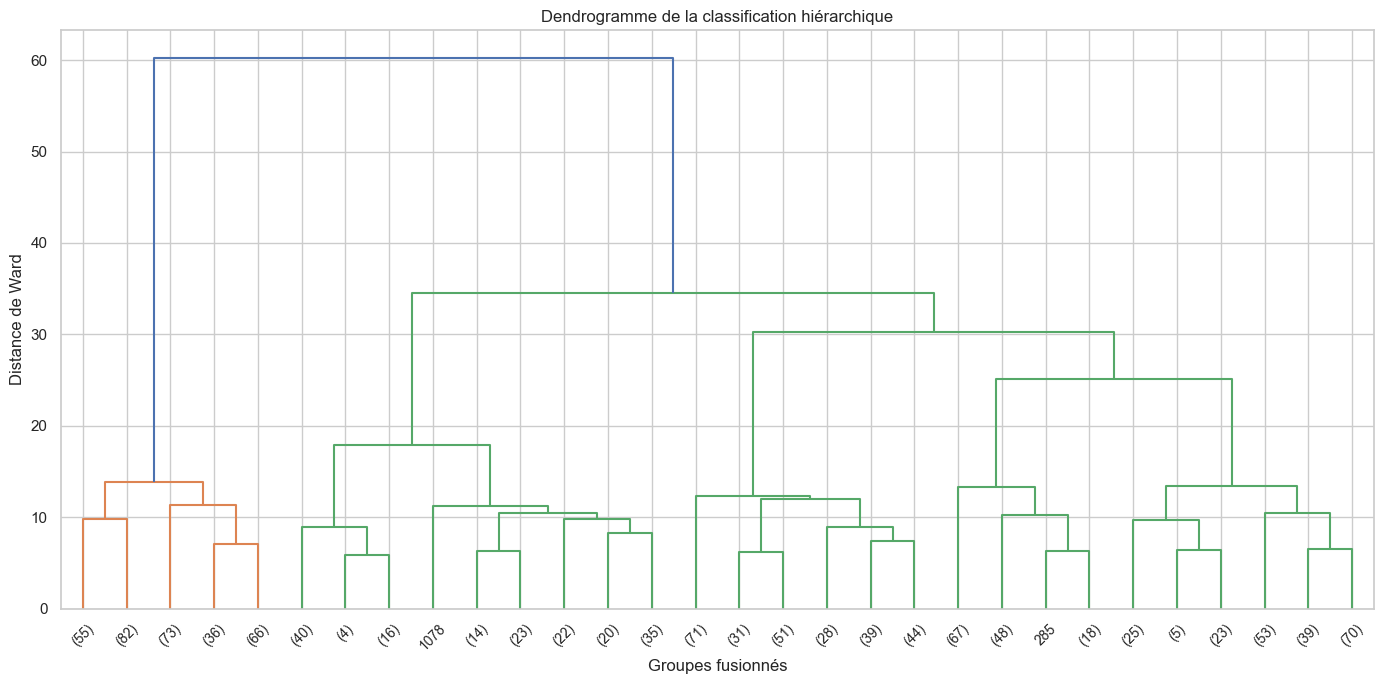

In [3]:
plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)

plt.title("Dendrogramme de la classification hiérarchique")
plt.xlabel("Groupes fusionnés")
plt.ylabel("Distance de Ward")

plt.tight_layout()
plt.show()

## 2. Choix du nombre de classes

Le dendrogramme présente une forte augmentation de la distance de fusion lors des
dernières étapes de la classification.

Une coupure en deux classes semble visuellement plausible, mais le choix du nombre de
groupes ne doit pas reposer uniquement sur l'inspection graphique.

Plusieurs solutions de classification sont donc comparées à l'aide d'indices de qualité :
le coefficient de silhouette, l'indice de Calinski-Harabasz et l'indice de
Davies-Bouldin.

In [4]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

In [5]:
resultats_clusters = []

for k in range(2, 9):

    labels = fcluster(
        Z,
        t=k,
        criterion="maxclust"
    )

    resultats_clusters.append({
        "k": k,
        "silhouette": silhouette_score(coord_pca, labels),
        "calinski_harabasz": calinski_harabasz_score(coord_pca, labels),
        "davies_bouldin": davies_bouldin_score(coord_pca, labels)
    })

resultats_clusters = pd.DataFrame(resultats_clusters)

resultats_clusters

,k,silhouette,calinski_harabasz,davies_bouldin
0,2,0.330880,606.976552,0.962811
1,3,0.266530,492.032270,1.336710
2,4,0.247064,469.812224,1.331869
3,5,0.261372,454.886753,1.159245
4,6,0.257833,416.389362,1.190731
5,7,0.201042,377.251048,1.321846
6,8,0.184989,350.729780,1.350195


In [6]:
for k in range(2, 9):

    labels = fcluster(
        Z,
        t=k,
        criterion="maxclust"
    )

    print(f"\n=== {k} classes ===")
    print(pd.Series(labels).value_counts().sort_index())


=== 2 classes ===
1    312
2    788
Name: count, dtype: int64

=== 3 classes ===
1    312
2    175
3    613
Name: count, dtype: int64

=== 4 classes ===
1    312
2    175
3    264
4    349
Name: count, dtype: int64

=== 5 classes ===
1    312
2    175
3    264
4    134
5    215
Name: count, dtype: int64

=== 6 classes ===
1    312
2     60
3    115
4    264
5    134
6    215
Name: count, dtype: int64

=== 7 classes ===
1    137
2    175
3     60
4    115
5    264
6    134
7    215
Name: count, dtype: int64

=== 8 classes ===
1    137
2    175
3     60
4    115
5    264
6    134
7     53
8    162
Name: count, dtype: int64


In [7]:
distances_finales = Z[-10:, 2]

print("Dernières distances de fusion :")
print(distances_finales)

print("\nÉcarts entre les dernières fusions :")
print(np.diff(distances_finales))

Dernières distances de fusion :
[12.0323368  12.35344414 13.30895103 13.46115589 13.85225938 17.84251431
 25.08573535 30.23287136 34.51097611 60.23450642]

Écarts entre les dernières fusions :
[ 0.32110734  0.95550689  0.15220487  0.39110349  3.99025493  7.24322104
  5.14713601  4.27810476 25.72353031]


### Choix retenu

Les trois indices de validation convergent vers une solution à deux classes.

Pour `k = 2`, le coefficient de silhouette est maximal (`0,331`), l'indice de
Calinski-Harabasz est également maximal (`606,98`) et l'indice de Davies-Bouldin
est minimal (`0,963`).

Cette solution est cohérente avec le dendrogramme, qui présente une forte augmentation
de la distance lors de la dernière fusion.

Les deux classes contiennent respectivement 312 et 788 observations.

La séparation reste toutefois modérée, comme l'indique la valeur de silhouette,
ce qui signifie que les profils ne forment pas deux groupes totalement disjoints.

In [8]:
labels = fcluster(
    Z,
    t=2,
    criterion="maxclust"
)

df["Cluster"] = labels

In [9]:
profil_clusters = (
    df.groupby("Cluster")[variables_combat]
    .mean()
    .round(2)
)

profil_clusters

,PV,Attaque,Defense,AttaqueSpeciale,DefenseSpeciale,Vitesse
Cluster,,,,,,
1,48.14,51.99,51.30,45.28,47.81,47.52
2,79.75,93.08,84.72,84.55,82.37,77.69


In [10]:
resume_clusters = (
    df.groupby("Cluster")
    .agg(
        effectif=("Nom", "count"),
        total_moyen=("Total", "mean"),
        total_median=("Total", "median"),
        proportion_legendaires=("Legendaire", "mean")
    )
)

resume_clusters["proportion_legendaires"] *= 100

resume_clusters.round(2)

,effectif,total_moyen,total_median,proportion_legendaires
Cluster,,,,
1,312,292.04,300.0,0.64
2,788,502.16,495.0,15.10


In [11]:
for cluster in sorted(df["Cluster"].unique()):

    print(f"\n=== Cluster {cluster} ===")

    display(
        df[df["Cluster"] == cluster]["Type1"]
        .value_counts(normalize=True)
        .head(8)
        .mul(100)
        .round(2)
    )


=== Cluster 1 ===


Type1
Eau        14.42
Normal     13.14
Insecte    10.26
Plante      9.94
Poison      5.45
Psy         5.13
Roche       5.13
Feu         4.81
Name: proportion, dtype: float64


=== Cluster 2 ===


Type1
Eau         12.06
Normal      10.15
Plante       8.38
Psy          7.99
Feu          7.11
Insecte      6.60
Électrik     6.22
Roche        5.33
Name: proportion, dtype: float64

## 3. Caractérisation des classes

La solution retenue distingue deux groupes présentant des niveaux de statistiques
très différents.

Le cluster 1 contient 312 observations. Il regroupe des Pokémon aux statistiques
globalement faibles, avec un `Total` moyen de 292,04 et une médiane de 300.

Le cluster 2 contient 788 observations. Les Pokémon de ce groupe possèdent des
statistiques nettement plus élevées, avec un `Total` moyen de 502,16 et une médiane
de 495.

Le statut légendaire différencie également fortement les deux classes : seuls 0,64 %
des Pokémon du cluster 1 sont légendaires, contre 15,10 % dans le cluster 2.

Les distributions des types principaux restent en revanche relativement proches entre
les deux groupes. La classification semble donc principalement structurée par le niveau
général des statistiques plutôt que par le type principal.

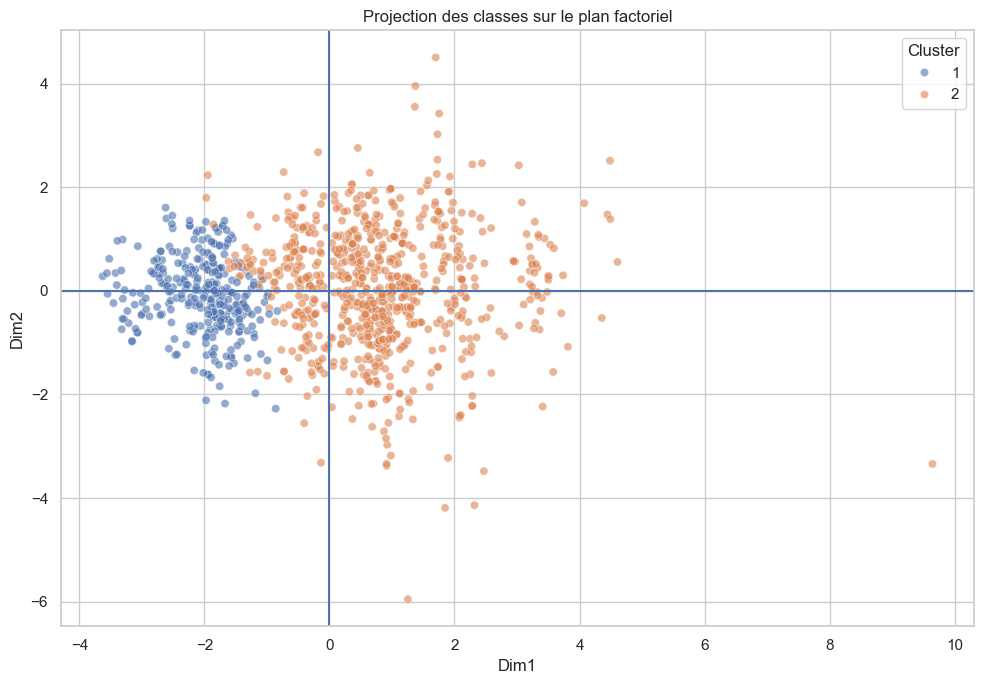

In [12]:
coord_plot = coord_pca.copy()
coord_plot["Cluster"] = df["Cluster"].astype(str)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=coord_plot,
    x="Dim1",
    y="Dim2",
    hue="Cluster",
    alpha=0.6
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Dim1")
plt.ylabel("Dim2")
plt.title("Projection des classes sur le plan factoriel")

plt.tight_layout()
plt.show()

In [13]:
coord_pca["Cluster"] = df["Cluster"]

representants = []

for cluster in sorted(df["Cluster"].unique()):

    sous_ensemble = coord_pca[
        coord_pca["Cluster"] == cluster
    ][["Dim1", "Dim2", "Dim3"]]

    centre = sous_ensemble.mean()

    distances = np.sqrt(
        ((sous_ensemble - centre) ** 2).sum(axis=1)
    )

    indices = distances.nsmallest(10).index

    tableau = df.loc[
        indices,
        ["Nom", "Type1", "Legendaire", "Total", "Cluster"]
    ]

    print(f"\n=== Pokémon représentatifs du cluster {cluster} ===")
    display(tableau)


=== Pokémon représentatifs du cluster 1 ===


,Nom,Type1,Legendaire,Total,Cluster
187,Métamorph,Normal,False,288.0,1
457,Stalgamin,Glace,False,300.0,1
714,Couaneton,Eau,False,305.0,1
894,Larvibule,Insecte,False,300.0,1
411,Chamallot,Feu,False,305.0,1
209,Minidraco,Dragon,False,300.0,1
1028,Grillepattes,Feu,False,305.0,1
34,Abo,Poison,False,288.0,1
322,Embrylex,Roche,False,300.0,1
830,Sepiatop,Ténèbres,False,288.0,1



=== Pokémon représentatifs du cluster 2 ===


,Nom,Type1,Legendaire,Total,Cluster
1089,Sylveroy,Psy,True,500.0,2
938,Dodoala,Normal,False,480.0,2
572,Blizzaroi,Plante,False,494.0,2
764,Gueriaigle de Hisui,Psy,False,510.0,2
47,Nidoqueen,Poison,False,505.0,2
588,Gallame,Psy,False,518.0,2
829,Cupcanaille,Fée,False,480.0,2
458,Oniglali,Glace,False,480.0,2
611,Phione,Eau,True,480.0,2
378,Brouhabam,Normal,False,490.0,2


## 4. Interprétation finale de la classification

La projection des classes sur le plan factoriel montre que la séparation repose
principalement sur Dim1, qui correspond à un gradient de puissance générale.

Le cluster 1 regroupe majoritairement des Pokémon aux statistiques faibles, situés
du côté négatif de Dim1. Ses représentants sont par exemple Métamorph, Stalgamin,
Couaneton ou Embrylex, dont les `Total` sont proches de 300.

Le cluster 2 rassemble des Pokémon aux statistiques nettement plus élevées. Parmi
ses représentants figurent notamment Nidoqueen, Gallame, Blizzaroi ou Sylveroy,
avec des `Total` généralement proches de 500.

Les types principaux sont variés dans les deux groupes. La classification ne semble
donc pas correspondre à une séparation par type, mais principalement à une différence
de niveau global des statistiques.

La séparation reste toutefois modérée, ce qui est cohérent avec le coefficient de
silhouette obtenu. Les deux classes constituent donc une synthèse utile des profils,
sans former deux groupes totalement disjoints.

## Conclusion de la CAH

La classification ascendante hiérarchique réalisée sur les trois premières composantes
de l'ACP met en évidence deux groupes principaux.

Le premier rassemble des Pokémon globalement faibles, tandis que le second regroupe
des profils plus puissants et contient une proportion nettement plus importante de
Pokémon légendaires.

Cette classification complète l'ACP en transformant le gradient continu de puissance
en deux groupes interprétables.